# Machine Learning - Niveau 4

## Apprentissage supervisé : comparer les classifieurs

Les niveaux précédents ont chacun traité une seule famille de modèles à la fois. L'[analyse bancaire](IA_ING_ML0_data_analysis.ipynb) préparait la cible `y`. Le [niveau 1](ML_1.ipynb) comparait arbre, forêt et régression logistique sur une souscription bancaire. Le [niveau 2](ML_2_svm_knn_random_forest.ipynb) comparait SVM, KNN et forêt sur des essences forestières. Le [niveau 3](ML_3_apprentissage_non_supervisé_clustering_kmean.ipynb) regroupait des observations sans étiquette, avec les k-moyennes.

Ce niveau revient à l'apprentissage supervisé, avec deux objectifs.

- **Regarder à l'intérieur.** Le classifieur du plus proche centroïde est codé pas à pas, comme les k-moyennes au niveau 3. Il sert de repère simple avant les modèles de bibliothèque.
- **Lire une frontière de décision.** Sur un jeu à deux attributs, on peut dessiner la zone que chaque classifieur attribue à chaque classe. Cette lecture explique pourquoi un classifieur réussit ou échoue, au-delà d'un seul chiffre de précision.

Le parcours se termine sur un cas réel à haute dimension : reconnaître une personne parmi sept, à partir de photographies. La leçon du niveau 1 sur les classes déséquilibrées y réapparaît sous une autre forme.

**Parcours**

| Section | Question |
|---|---|
| 1 | Quatre classifieurs, quatre idées : que retenir avant de coder ? |
| 2 | À quoi ressemble un jeu de classification à trois classes ? |
| 3 | Comment lire une frontière de décision ? |
| 4 | Que fait le classifieur du plus proche centroïde ? |
| 5 | Comment les k plus proches voisins votent-ils ? |
| 6 | Comment un arbre découpe-t-il l'espace ? |
| 7 | Pourquoi une forêt lisse-t-elle les erreurs d'un arbre ? |
| 8 | Quel classifieur choisir sur ce jeu précis ? |
| 9 | Quelles formes chaque classifieur retrouve-t-il ? |
| 10 | Un modèle précis reconnaît-il vraiment chaque personne ? |


## 1. Quatre idées de classification

Les quatre classifieurs de ce notebook répondent tous à la même question — à quelle classe appartient cette observation ? — avec des géométries différentes.

| Classifieur | Idée | Ce qu'il suppose implicitement |
|---|---|---|
| Plus proche centroïde | Comparer `x` à la moyenne de chaque classe | Les classes forment des paquets ronds, de taille comparable |
| k plus proches voisins | Faire voter les `k` exemples d'entraînement les plus proches | Les voisins d'un point partagent en général sa classe |
| Arbre de décision | Empiler des règles de seuil sur un attribut à la fois | Une frontière utile peut s'écrire avec des coupes parallèles aux axes |
| Forêt aléatoire | Moyenner les votes de nombreux arbres légèrement différents | Les erreurs d'un arbre isolé se compensent en partie entre arbres |

Ces hypothèses ne sont jamais vraies exactement. Elles le sont plus ou moins selon les données, ce que la section 9 montrera sur des formes contrastées.


### Installer les dépendances et préparer les outils


In [1]:
%pip install -q scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import (
    load_digits,
    make_blobs,
    make_circles,
    make_classification,
    make_moons,
)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.tree import DecisionTreeClassifier

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## 2. Un jeu à trois classes, entraînement et test

Le jeu est simulé en deux dimensions, pour pouvoir dessiner les frontières de décision. Les trois classes se chevauchent un peu : certains points sont proches d'une frontière naturelle, ce qui empêche un score parfait et rend les comparaisons informatives.

Comme au niveau 1 : « pour apprendre une chose nouvelle à un élève, on lui fait faire des exercices et on les corrige. Une fois qu'on juge qu'il a appris, on lui fait passer un contrôle et on le compare à la correction pour obtenir sa note. Un bon professeur ne met jamais dans le contrôle un exercice déjà vu en cours. » Le jeu d'entraînement sert à ajuster les classifieurs ; le jeu de test, mis de côté dès maintenant, sert uniquement à les comparer à la fin.


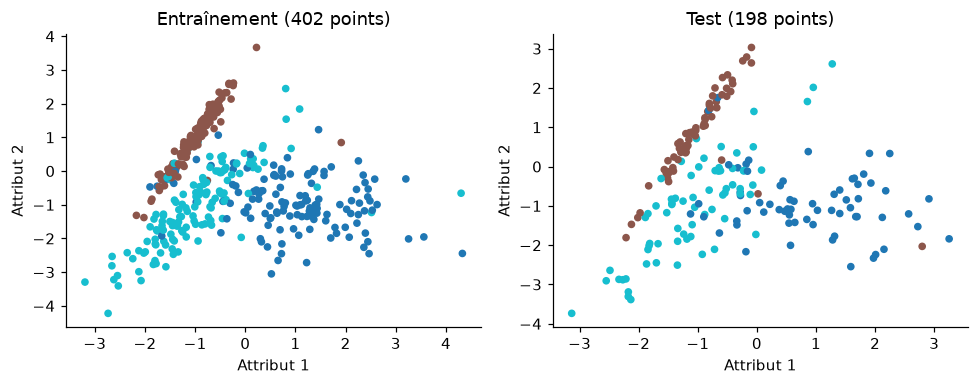

Effectifs par classe, entraînement : [132, 130, 140]
Effectifs par classe, test : [65, 64, 69]


In [3]:
X, y = make_classification(
    n_samples=600,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    n_classes=3,
    class_sep=1.0,
    flip_y=0.05,
    random_state=7,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=666, stratify=y
)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=16, cmap="tab10")
axes[0].set_title(f"Entraînement ({len(y_train)} points)")
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=16, cmap="tab10")
axes[1].set_title(f"Test ({len(y_test)} points)")
for ax in axes:
    ax.set_xlabel("Attribut 1")
    ax.set_ylabel("Attribut 2")
fig.tight_layout()
plt.show()

print("Effectifs par classe, entraînement :", np.bincount(y_train).tolist())
print("Effectifs par classe, test :", np.bincount(y_test).tolist())


### Lire ces deux figures

Les trois classes sont visiblement proches par endroits, notamment entre les couleurs orange et bleue. Les effectifs sont proches d'un tiers chacun, dans les deux jeux : la stratification (`stratify=y`) a conservé cette proportion malgré le découpage aléatoire. Avec des classes presque équilibrées, l'exactitude (la part de bonnes réponses) et le F1 macro (la moyenne du F1 de chaque classe, chacune comptant pour un tiers) resteront proches l'un de l'autre dans cette section. Ce ne sera plus le cas à la section 10.


## 3. Un repère commun : la frontière de décision

Une **frontière de décision** découpe le plan des attributs en régions, une par classe. Chaque région contient les points que le classifieur attribue à cette classe. Elle se dessine en calculant la prédiction sur une grille fine de points fictifs, puis en coloriant chaque case de la grille selon la classe prédite.

Les deux fonctions ci-dessous sont réutilisées pour chaque classifieur : `tracer_frontiere` dessine la grille colorée et les points de test par-dessus ; `evaluer` calcule l'exactitude et le F1 macro sur le jeu de test, puis appelle `tracer_frontiere`. Elles acceptent n'importe quelle fonction de prédiction, codée à la main ou fournie par scikit-learn.


In [4]:
def tracer_frontiere(ax, predire, X_train, y_train, X_test, y_test, titre, resolution=250):
    """Dessine la région attribuée à chaque classe, puis les points de test par-dessus."""
    x_min, x_max = X_train[:, 0].min() - 0.6, X_train[:, 0].max() + 0.6
    y_min, y_max = X_train[:, 1].min() - 0.6, X_train[:, 1].max() + 0.6
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, resolution), np.linspace(y_min, y_max, resolution)
    )
    grille = np.column_stack([xx.ravel(), yy.ravel()])
    zz = predire(grille).reshape(xx.shape)
    n_classes = len(np.unique(y_train))
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="tab10", levels=np.arange(-0.5, n_classes + 0.5, 1))
    ax.scatter(
        X_test[:, 0], X_test[:, 1], c=y_test, cmap="tab10", s=16, edgecolor="black", linewidth=0.3
    )
    ax.set_title(titre)
    ax.set_xticks([])
    ax.set_yticks([])


def evaluer(nom, predire, X_train, y_train, X_test, y_test, afficher=True):
    """Calcule exactitude et F1 macro sur le test, puis affiche la frontière si demandé."""
    y_pred = predire(X_test)
    exactitude = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    print(f"{nom:28} exactitude {exactitude:.3f}   F1 macro {f1_macro:.3f}")
    if afficher:
        fig, ax = plt.subplots(figsize=(4.2, 3.8))
        tracer_frontiere(ax, predire, X_train, y_train, X_test, y_test, nom)
        fig.tight_layout()
        plt.show()
    return {"nom": nom, "exactitude": exactitude, "f1_macro": f1_macro, "y_pred": y_pred}


## 4. Le classifieur du plus proche centroïde

Pour chaque classe `c`, on calcule son **centroïde** : la moyenne de tous les points d'entraînement de cette classe.

$$
\mu_c = \frac{1}{|\{i : y_i = c\}|} \sum_{i : y_i = c} x_i
$$

Un nouveau point reçoit la classe dont le centroïde est le plus proche.

$$
\hat y(x) = \arg\min_{c} \| x - \mu_c \|
$$

C'est le classifieur le plus simple du notebook. Sa frontière entre deux classes est une droite à égale distance des deux centroïdes, exactement comme la frontière entre deux centres de k-moyennes au niveau 3.


Plus proche centroïde        exactitude 0.778   F1 macro 0.781


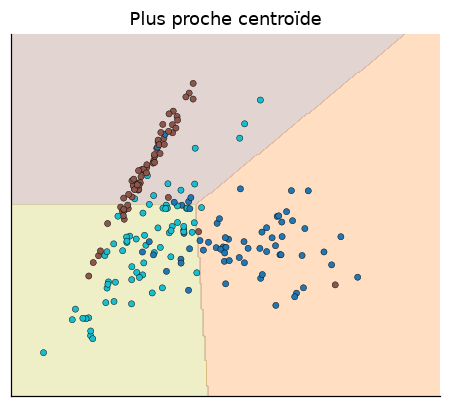

In [5]:
def entrainer_centroide(X_entrainement, y_entrainement):
    """Calcule le centroïde de chaque classe."""
    classes = np.unique(y_entrainement)
    centroides = np.array([X_entrainement[y_entrainement == c].mean(axis=0) for c in classes])
    return classes, centroides


def predire_centroide(X_nouveau, classes, centroides):
    """Attribue à chaque point la classe du centroïde le plus proche."""
    distances = np.linalg.norm(X_nouveau[:, None, :] - centroides[None, :, :], axis=2)
    return classes[distances.argmin(axis=1)]


classes_train, centroides_train = entrainer_centroide(X_train, y_train)
resultat_centroide = evaluer(
    "Plus proche centroïde",
    lambda X_nouveau: predire_centroide(X_nouveau, classes_train, centroides_train),
    X_train,
    y_train,
    X_test,
    y_test,
)


### Interpréter le centroïde

L'exactitude vaut **0,778** et le F1 macro **0,781** : proches l'un de l'autre, parce que les classes restent à peu près équilibrées. Les trois régions colorées sont séparées par des segments de droite : chaque frontière est à égale distance de deux centroïdes, quelle que soit la dispersion réelle des points autour d'eux. Un point excentré, loin de son propre groupe mais du bon côté de cette droite, est tout de même bien classé ; un point proche de la frontière peut basculer du mauvais côté. C'est le repère du notebook : les trois classifieurs suivants chercheront à faire mieux, avec des frontières plus souples.


## 5. k plus proches voisins (KNN)

Pour classer un nouveau point, le KNN cherche ses `k` voisins les plus proches dans le jeu d'entraînement, et lui attribue la classe majoritaire parmi eux. Contrairement au centroïde, il ne résume jamais une classe à un seul point : toute la mémoire d'entraînement reste disponible au moment de prédire.

`k` est un réglage à choisir. Un `k` petit colle aux exemples d'entraînement, y compris à leur bruit : c'est le **surapprentissage**. Un `k` grand moyenne sur un voisinage large et finit par ignorer la structure locale : c'est le **sous-apprentissage**. On choisit `k` par validation croisée sur le seul jeu d'entraînement, comme au niveau 1 pour les hyperparamètres du niveau 2.


Meilleur k en validation croisée : 10 (exactitude moyenne 0.900)


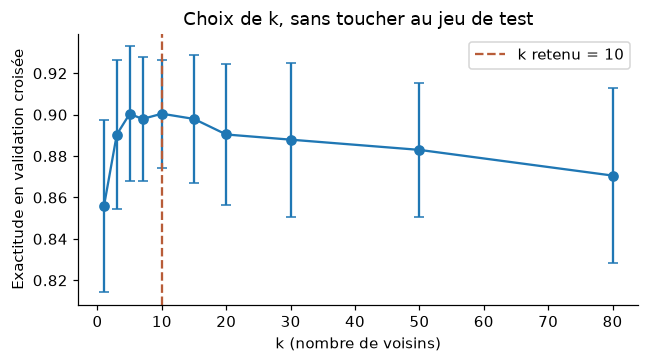

In [6]:
valeurs_de_k = [1, 3, 5, 7, 10, 15, 20, 30, 50, 80]
validation_croisee = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

moyennes_knn = []
ecarts_types_knn = []
for k in valeurs_de_k:
    scores = cross_val_score(
        KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=validation_croisee
    )
    moyennes_knn.append(scores.mean())
    ecarts_types_knn.append(scores.std())

meilleur_k = valeurs_de_k[int(np.argmax(moyennes_knn))]
print(f"Meilleur k en validation croisée : {meilleur_k} (exactitude moyenne {max(moyennes_knn):.3f})")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.errorbar(valeurs_de_k, moyennes_knn, yerr=ecarts_types_knn, marker="o", capsize=3)
ax.axvline(meilleur_k, color="#b85c38", linestyle="--", label=f"k retenu = {meilleur_k}")
ax.set_xlabel("k (nombre de voisins)")
ax.set_ylabel("Exactitude en validation croisée")
ax.set_title("Choix de k, sans toucher au jeu de test")
ax.legend()
fig.tight_layout()
plt.show()


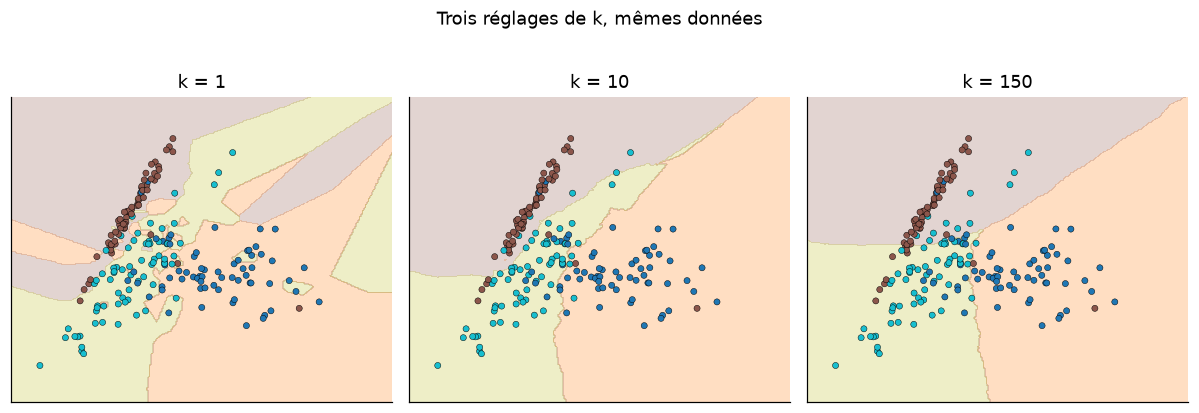

KNN (k=10)                   exactitude 0.843   F1 macro 0.845


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, k in zip(axes, (1, meilleur_k, 150)):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    tracer_frontiere(ax, knn.predict, X_train, y_train, X_test, y_test, f"k = {k}")
fig.suptitle("Trois réglages de k, mêmes données", y=1.03)
fig.tight_layout()
plt.show()

knn_final = KNeighborsClassifier(n_neighbors=meilleur_k).fit(X_train, y_train)
resultat_knn = evaluer(
    f"KNN (k={meilleur_k})", knn_final.predict, X_train, y_train, X_test, y_test, afficher=False
)


### Interpréter le choix de k

La courbe de validation croisée monte de **0,856** (`k=1`) à un plateau autour de **0,90** entre `k=5` et `k=10`, puis redescend doucement jusqu'à **0,871** (`k=80`). Le minimum à gauche est le surapprentissage : avec un seul voisin, un point bruité isolé devient sa propre règle. La baisse à droite est le sous-apprentissage : avec 80 voisins sur 402 exemples d'entraînement, chaque vote se rapproche d'une moyenne globale.

Le classifieur retenu a **k = 10**. Sur le jeu de test, resté à l'écart de ce réglage, il obtient une exactitude de **0,843** et un F1 macro de **0,845** — nettement au-dessus du centroïde.

Les trois frontières dessinées le confirment. À `k=1`, la frontière est déchiquetée : chaque point d'entraînement crée sa propre petite région. À `k=10`, les régions sont lisses et suivent la forme réelle des classes, y compris leur léger chevauchement. À `k=150`, les frontières redeviennent presque rectilignes, proches de celles du centroïde : avec autant de voisins, la majorité locale se rapproche d'une tendance globale.


## 6. Arbre de décision

Un arbre de décision pose une suite de questions du type « cet attribut dépasse-t-il tel seuil ? ». Chaque réponse sépare l'espace en deux par une droite parallèle à un axe. Empilées, ces coupes découpent le plan en rectangles, chacun associé à une classe majoritaire.

La **profondeur maximale** limite le nombre de questions posées à la suite. Comme pour `k`, elle se choisit par validation croisée sur l'entraînement.


Meilleure profondeur en validation croisée : 6 (exactitude moyenne 0.861)


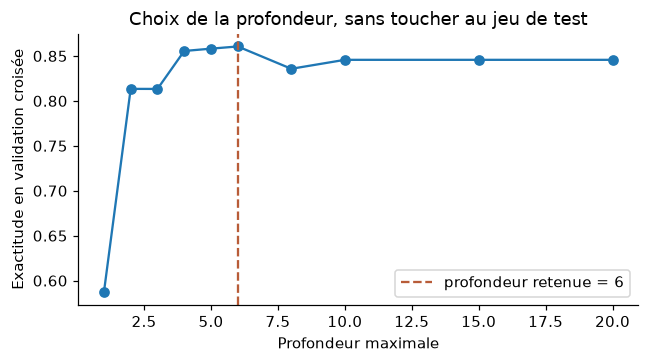

In [8]:
profondeurs = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]

moyennes_arbre = []
for profondeur in profondeurs:
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=profondeur, random_state=0),
        X_train,
        y_train,
        cv=validation_croisee,
    )
    moyennes_arbre.append(scores.mean())

meilleure_profondeur = profondeurs[int(np.argmax(moyennes_arbre))]
print(
    f"Meilleure profondeur en validation croisée : {meilleure_profondeur} "
    f"(exactitude moyenne {max(moyennes_arbre):.3f})"
)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(profondeurs, moyennes_arbre, marker="o")
ax.axvline(meilleure_profondeur, color="#b85c38", linestyle="--", label=f"profondeur retenue = {meilleure_profondeur}")
ax.set_xlabel("Profondeur maximale")
ax.set_ylabel("Exactitude en validation croisée")
ax.set_title("Choix de la profondeur, sans toucher au jeu de test")
ax.legend()
fig.tight_layout()
plt.show()


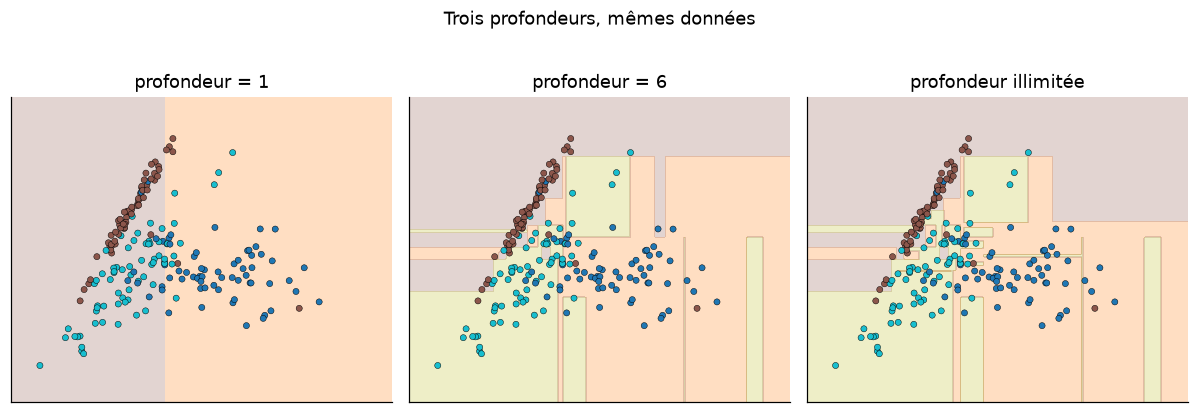

Arbre (profondeur=6)         exactitude 0.828   F1 macro 0.829


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, profondeur, titre in zip(
    axes,
    (1, meilleure_profondeur, None),
    (f"profondeur = 1", f"profondeur = {meilleure_profondeur}", "profondeur illimitée"),
):
    arbre = DecisionTreeClassifier(max_depth=profondeur, random_state=0).fit(X_train, y_train)
    tracer_frontiere(ax, arbre.predict, X_train, y_train, X_test, y_test, titre)
fig.suptitle("Trois profondeurs, mêmes données", y=1.03)
fig.tight_layout()
plt.show()

arbre_final = DecisionTreeClassifier(max_depth=meilleure_profondeur, random_state=0).fit(X_train, y_train)
resultat_arbre = evaluer(
    f"Arbre (profondeur={meilleure_profondeur})",
    arbre_final.predict,
    X_train,
    y_train,
    X_test,
    y_test,
    afficher=False,
)


### Interpréter le choix de la profondeur

Avec une seule question (`profondeur=1`), l'exactitude en validation croisée plafonne à **0,587** : un seul seuil ne peut pas séparer trois classes qui s'enchevêtrent. Elle grimpe à **0,858** vers `profondeur=5`, atteint **0,861** à `profondeur=6`, puis redescend légèrement et se stabilise autour de **0,846** au-delà de `profondeur=10`. Passé ce point, l'arbre ajoute des coupes qui séparent des points de bruit plutôt que les classes elles-mêmes.

Le classifieur retenu a une **profondeur de 6**. Sur le test, il obtient une exactitude de **0,828** et un F1 macro de **0,829**, un peu sous le KNN. Les figures le montrent : à profondeur 1, une seule ligne droite coupe le plan en deux, laissant la troisième classe mal desservie. À profondeur 6, les rectangles suivent d'assez près les trois classes. Sans limite de profondeur, l'arbre ajoute de petits rectangles isolés autour de points uniques, visibles comme de fines bandes colorées : un signe classique de surapprentissage, cohérent avec la légère baisse de la courbe de validation.


## 7. Forêt aléatoire

Une forêt aléatoire entraîne de nombreux arbres, chacun sur un tirage aléatoire des observations et des attributs disponibles à chaque coupe. Pour prédire, elle fait voter tous les arbres et retient la classe majoritaire.

Deux arbres entraînés sur des tirages différents ne se trompent pas forcément sur les mêmes points. En les moyennant, la forêt lisse une partie de ces erreurs. Contrairement à `k` ou à la profondeur, ajouter des arbres ne fait pas réapparaître de surapprentissage : au pire, l'amélioration ralentit.


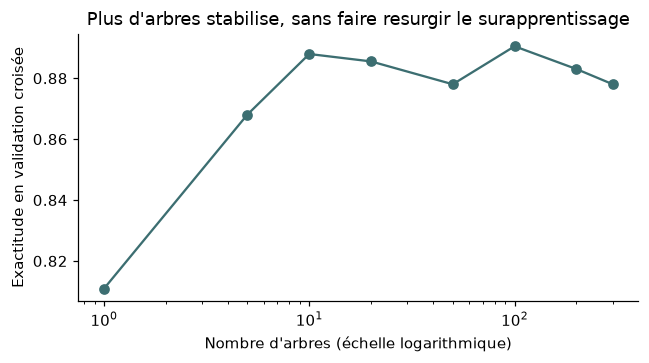

n_estimators=   1  exactitude CV moyenne 0.811
n_estimators=   5  exactitude CV moyenne 0.868
n_estimators=  10  exactitude CV moyenne 0.888
n_estimators=  20  exactitude CV moyenne 0.886
n_estimators=  50  exactitude CV moyenne 0.878
n_estimators= 100  exactitude CV moyenne 0.890
n_estimators= 200  exactitude CV moyenne 0.883
n_estimators= 300  exactitude CV moyenne 0.878


In [10]:
nombres_darbres = [1, 5, 10, 20, 50, 100, 200, 300]

moyennes_foret = []
for n in nombres_darbres:
    scores = cross_val_score(
        RandomForestClassifier(n_estimators=n, random_state=0), X_train, y_train, cv=validation_croisee
    )
    moyennes_foret.append(scores.mean())

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(nombres_darbres, moyennes_foret, marker="o", color="#3c6e71")
ax.set_xscale("log")
ax.set_xlabel("Nombre d'arbres (échelle logarithmique)")
ax.set_ylabel("Exactitude en validation croisée")
ax.set_title("Plus d'arbres stabilise, sans faire resurgir le surapprentissage")
fig.tight_layout()
plt.show()

for n, moyenne in zip(nombres_darbres, moyennes_foret):
    print(f"n_estimators={n:4}  exactitude CV moyenne {moyenne:.3f}")


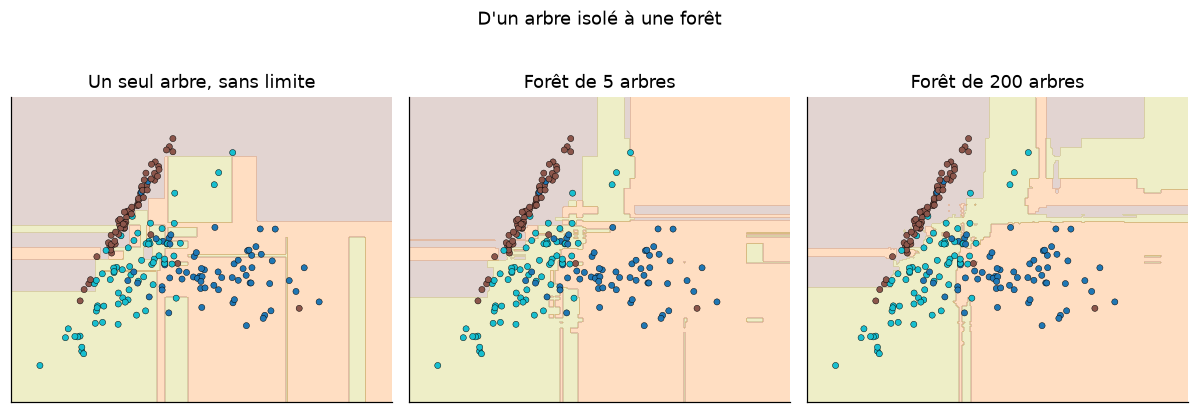

Forêt (200 arbres)           exactitude 0.848   F1 macro 0.850


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
arbre_isole = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
tracer_frontiere(axes[0], arbre_isole.predict, X_train, y_train, X_test, y_test, "Un seul arbre, sans limite")
foret_5 = RandomForestClassifier(n_estimators=5, random_state=0).fit(X_train, y_train)
tracer_frontiere(axes[1], foret_5.predict, X_train, y_train, X_test, y_test, "Forêt de 5 arbres")
foret_200 = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_train, y_train)
tracer_frontiere(axes[2], foret_200.predict, X_train, y_train, X_test, y_test, "Forêt de 200 arbres")
fig.suptitle("D'un arbre isolé à une forêt", y=1.03)
fig.tight_layout()
plt.show()

resultat_foret = evaluer(
    "Forêt (200 arbres)", foret_200.predict, X_train, y_train, X_test, y_test, afficher=False
)


### Interpréter la forêt

La courbe de validation croisée passe de **0,811** (1 arbre) à **0,888** (10 arbres), puis oscille entre **0,878** et **0,890** au-delà de 20 arbres, sans tendance claire à se dégrader. C'est la différence avec `k` et la profondeur : il n'y a pas de minimum caché à droite de la courbe, seulement un plateau.

Les frontières l'illustrent. L'arbre isolé, sans limite de profondeur, affiche les mêmes fines bandes de surapprentissage que dans la section précédente. La forêt de 5 arbres lisse déjà une partie de ces détails. La forêt de 200 arbres produit des régions proches de celles de l'arbre de profondeur 6, mais avec des bords plus réguliers : chaque petite erreur isolée d'un arbre est noyée dans le vote des 199 autres.

Avec 200 arbres, la forêt obtient une exactitude de test de **0,848** et un F1 macro de **0,850** : le meilleur résultat des quatre classifieurs sur ce jeu.


## 8. Comparer les quatre classifieurs

Le tableau rassemble les résultats de test déjà calculés, avec une baseline qui prédit toujours la classe la plus fréquente de l'entraînement — le même repère qu'au niveau 1.


In [12]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
resultat_baseline = evaluer(
    "Baseline (classe majoritaire)", baseline.predict, X_train, y_train, X_test, y_test, afficher=False
)

comparaison = [resultat_baseline, resultat_centroide, resultat_knn, resultat_arbre, resultat_foret]
print(f"{'Classifieur':30}{'Exactitude':>12}{'F1 macro':>12}")
for ligne in comparaison:
    print(f"{ligne['nom']:30}{ligne['exactitude']:12.3f}{ligne['f1_macro']:12.3f}")


Baseline (classe majoritaire) exactitude 0.348   F1 macro 0.172
Classifieur                     Exactitude    F1 macro
Baseline (classe majoritaire)        0.348       0.172
Plus proche centroïde                0.778       0.781
KNN (k=10)                           0.843       0.845
Arbre (profondeur=6)                 0.828       0.829
Forêt (200 arbres)                   0.848       0.850


### Lire la comparaison

| Classifieur | Exactitude | F1 macro |
|---|---:|---:|
| Baseline | 0,348 | 0,172 |
| Plus proche centroïde | 0,778 | 0,781 |
| KNN (k=10) | 0,843 | 0,845 |
| Arbre (profondeur=6) | 0,828 | 0,829 |
| Forêt (200 arbres) | 0,848 | 0,850 |

La baseline confirme qu'il n'y a pas de classe dominante à deviner par défaut : son exactitude de 0,348 est proche d'un tiers, attendu avec trois classes à peu près équilibrées, et son F1 macro chute à 0,172 car elle laisse deux classes sur trois sans aucune bonne réponse.

Les quatre classifieurs se classent dans l'ordre attendu depuis les sections précédentes : le centroïde en retrait (0,778), l'arbre légèrement en dessous du KNN (0,828 contre 0,843), et la forêt en tête (0,848). Les écarts entre KNN, arbre et forêt restent faibles au regard de l'écart-type observé pendant la validation croisée (autour de 0,03) : ce classement n'est pas à lire comme une supériorité définitive de la forêt sur ce type de données, seulement sur ce jeu précis. La section suivante montre que l'écart entre le centroïde et les trois autres se creuse ou se referme selon la forme du nuage de points.


## 9. Quelles formes chaque classifieur retrouve-t-il ?

Les quatre classifieurs gardent leurs réglages choisis plus haut (`k=10`, `profondeur=6`, `200 arbres`) sur six jeux différents. Seule la forme du nuage change. Cette section prolonge une question déjà posée au niveau 3 à propos des k-moyennes : la géométrie des données décide quel outil convient, pas seulement la quantité de données.


Jeu                       baseline  centroïde     knn   arbre   forêt

Blobs compacts               0.329      1.000   1.000   1.000   1.000


Groupes allongés             0.329      0.879   0.987   0.980   0.973


Lunes                        0.497      0.732   0.933   0.913   0.919


Cercles imbriqués            0.497      0.510   0.993   0.966   0.987


Variances inégales           0.329      0.946   0.987   0.966   0.973


Chiffres, projection 2D      0.201      0.836   0.872   0.879   0.883


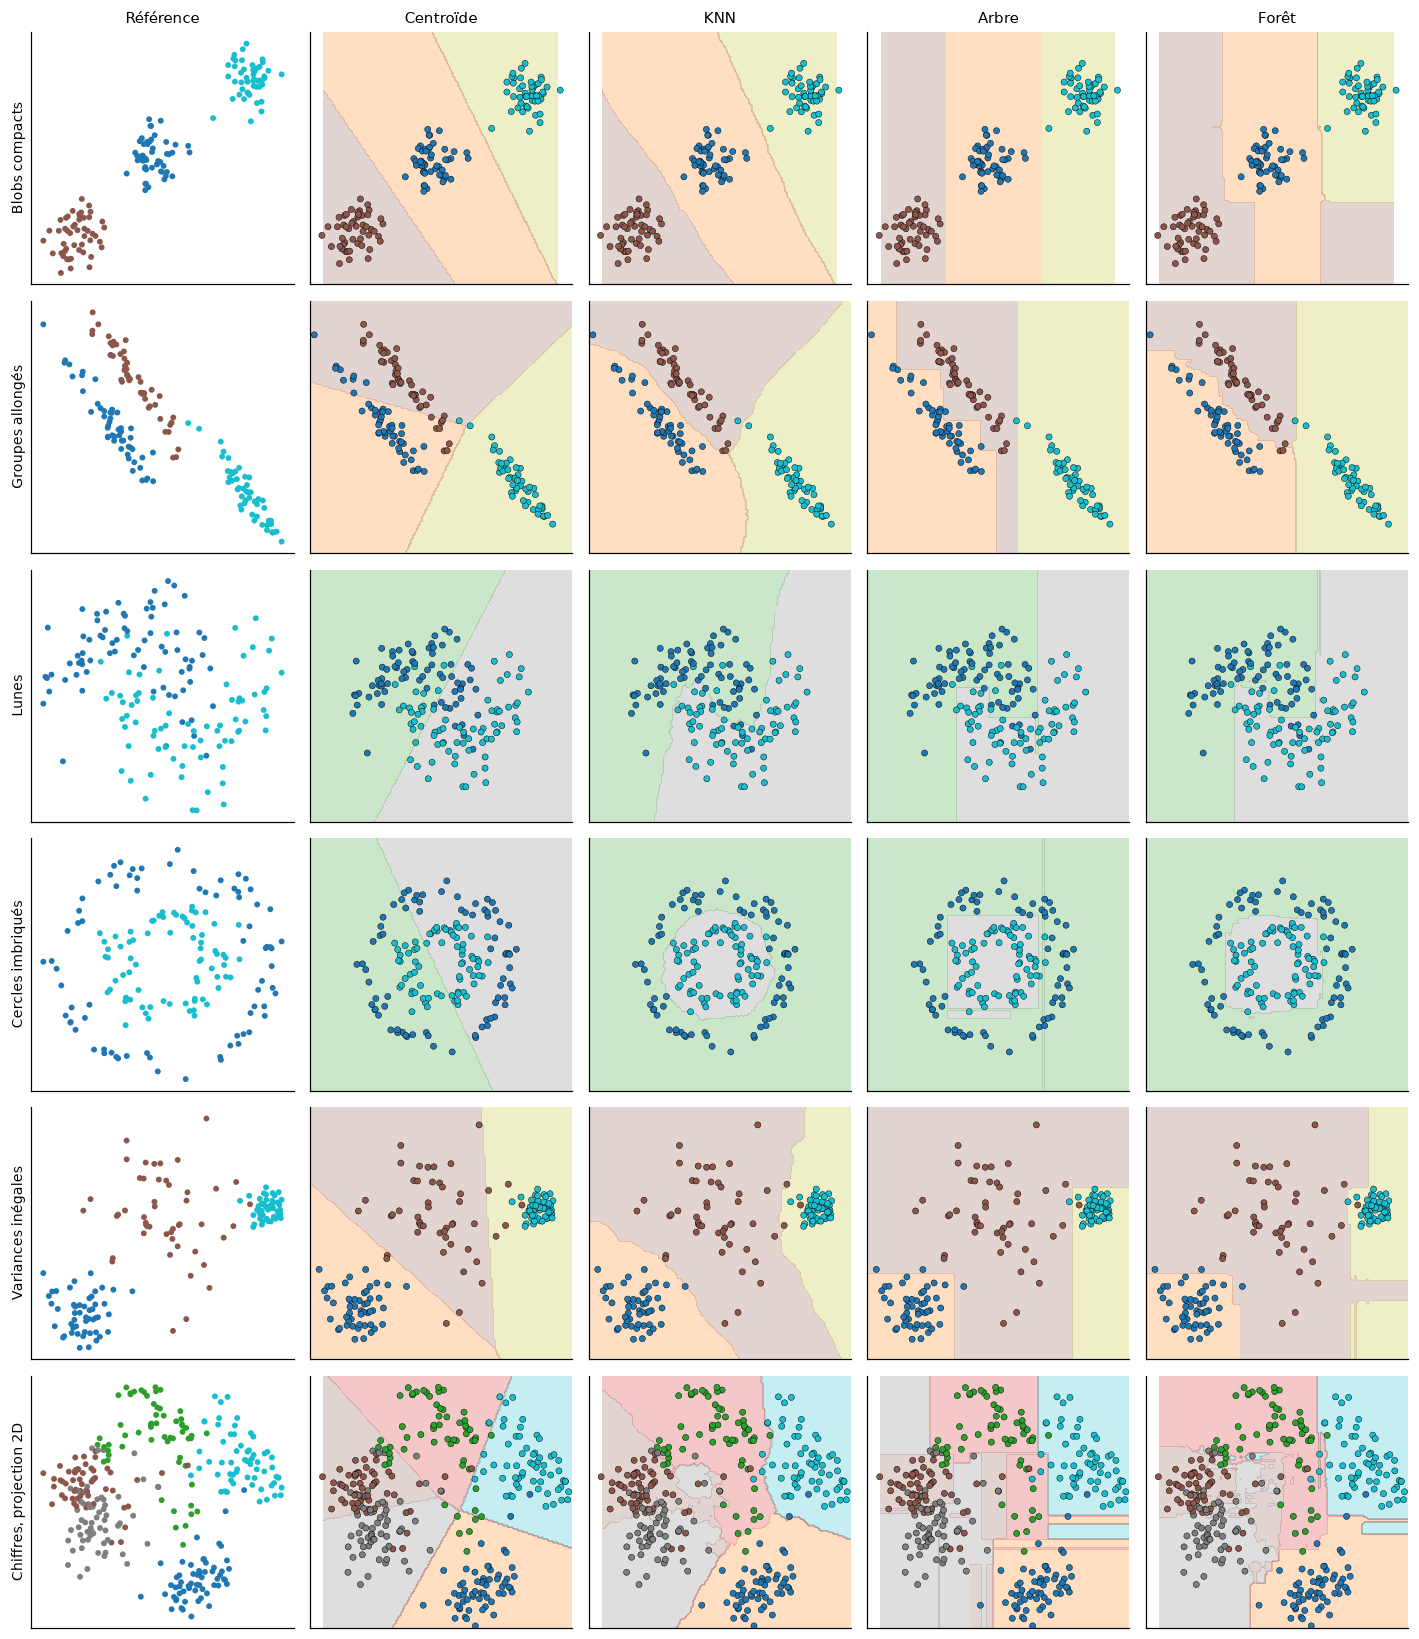

In [13]:
def jeux_de_classification(n_points=450, graine=3):
    """Six jeux de classification pour comparer la géométrie des classifieurs."""
    jeux = []

    X, y = make_blobs(n_samples=n_points, centers=3, cluster_std=0.9, random_state=graine)
    jeux.append(("Blobs compacts", X, y))

    X, y = make_blobs(n_samples=n_points, centers=3, random_state=170)
    X = X @ np.array([[0.6, -0.6], [-0.4, 0.8]])
    jeux.append(("Groupes allongés", X, y))

    X, y = make_moons(n_samples=n_points, noise=0.25, random_state=graine)
    jeux.append(("Lunes", X, y))

    X, y = make_circles(n_samples=n_points, factor=0.5, noise=0.1, random_state=graine)
    jeux.append(("Cercles imbriqués", X, y))

    X, y = make_blobs(
        n_samples=n_points, centers=3, cluster_std=[1.0, 2.2, 0.6], random_state=170
    )
    jeux.append(("Variances inégales", X, y))

    chiffres = load_digits(n_class=5)
    X = PCA(n_components=2, random_state=0).fit_transform(chiffres.data)
    y = chiffres.target
    jeux.append(("Chiffres, projection 2D", X, y))

    return jeux


jeux = jeux_de_classification()
fig, axes = plt.subplots(len(jeux), 5, figsize=(13, 2.5 * len(jeux)))
print(f"{'Jeu':24}{'baseline':>10}{'centroïde':>11}{'knn':>8}{'arbre':>8}{'forêt':>8}")

for ligne, (nom, X_jeu, y_jeu) in enumerate(jeux):
    X_app, X_eval, y_app, y_eval = train_test_split(
        X_jeu, y_jeu, test_size=0.33, random_state=666, stratify=y_jeu
    )

    base = DummyClassifier(strategy="most_frequent").fit(X_app, y_app)
    classes_j, centroides_j = entrainer_centroide(X_app, y_app)
    predire_centroide_j = lambda X_nouveau: predire_centroide(X_nouveau, classes_j, centroides_j)
    knn_j = KNeighborsClassifier(n_neighbors=10).fit(X_app, y_app)
    arbre_j = DecisionTreeClassifier(max_depth=6, random_state=0).fit(X_app, y_app)
    foret_j = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_app, y_app)

    accs = [
        accuracy_score(y_eval, base.predict(X_eval)),
        accuracy_score(y_eval, predire_centroide_j(X_eval)),
        accuracy_score(y_eval, knn_j.predict(X_eval)),
        accuracy_score(y_eval, arbre_j.predict(X_eval)),
        accuracy_score(y_eval, foret_j.predict(X_eval)),
    ]
    print(f"{nom:24}{accs[0]:10.3f}{accs[1]:11.3f}{accs[2]:8.3f}{accs[3]:8.3f}{accs[4]:8.3f}")

    ax = axes[ligne, 0]
    ax.scatter(X_eval[:, 0], X_eval[:, 1], c=y_eval, s=8, cmap="tab10")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_ylabel(nom, fontsize=9)
    if ligne == 0:
        ax.set_title("Référence", fontsize=10)

    for colonne, (predire, titre) in enumerate(
        (
            (predire_centroide_j, "Centroïde"),
            (knn_j.predict, "KNN"),
            (arbre_j.predict, "Arbre"),
            (foret_j.predict, "Forêt"),
        ),
        start=1,
    ):
        ax = axes[ligne, colonne]
        tracer_frontiere(ax, predire, X_app, y_app, X_eval, y_eval, "", resolution=150)
        if ligne == 0:
            ax.set_title(titre, fontsize=10)

fig.tight_layout()
plt.show()


### Lire la galerie

- **Blobs compacts.** Les quatre classifieurs atteignent **1,0**. C'est le cas le plus favorable : des paquets ronds, bien séparés, où même une frontière linéaire suffit.
- **Groupes allongés.** Le centroïde retombe à **0,879**, pendant que KNN, arbre et forêt restent entre **0,973** et **0,987**. Les trois classes sont étirées en diagonale : un point au bout d'un groupe peut être, en ligne droite, plus proche du centroïde d'un groupe voisin que du sien.
- **Lunes.** Le centroïde chute à **0,732**, à peine mieux que la référence à deux classes. KNN, arbre et forêt dépassent **0,91**. La frontière utile suit une courbe en S ; une droite entre deux centroïdes la coupe au mauvais endroit sur une bonne partie des points.
- **Cercles imbriqués.** Le centroïde tombe à **0,510**, soit le niveau de la baseline (0,497) : les deux centroïdes se superposent presque, puisque les deux cercles sont concentriques. KNN atteint **0,993**, l'arbre et la forêt dépassent **0,96**, en approximant le cercle par des petits segments ou des petits rectangles.
- **Variances inégales.** Le centroïde reste correct, à **0,946**, parce que les trois groupes restent assez séparés malgré leurs tailles différentes. Les trois autres classifieurs font un peu mieux (0,966 à 0,987).
- **Chiffres, projection 2D.** Cas réel à cinq classes, projetées en deux dimensions : toutes les méthodes reculent par rapport aux jeux simulés (0,836 à 0,883), parce que la projection a mêlé une partie de l'information utile. L'écart entre le centroïde et les trois autres s'y réduit, signe que les classes y restent relativement compactes malgré le chevauchement.

La règle qui se dégage rejoint celle du niveau 3 : le centroïde réussit quand les classes ressemblent à des boules de même taille, et échoue dès qu'elles sont étirées, courbes ou concentriques. KNN, arbre et forêt restent proches les uns des autres sur ces six jeux, avec un léger avantage régulier pour la forêt.


## 10. Un cas réel : qui est sur la photo ?

Le jeu [LFW (Labeled Faces in the Wild)](http://vis-www.cs.umass.edu/lfw/), inclus dans scikit-learn, contient des photographies de personnalités publiques. On garde les sept personnes qui ont au moins 70 photos, pour avoir assez d'exemples par classe. Chaque image de 62×47 pixels en niveaux de gris devient un vecteur de 2914 valeurs : un pixel, un attribut. Les quatre classifieurs sont appliqués tels quels sur ces 2914 attributs, avec les réglages choisis plus haut.

Contrairement aux jeux précédents, les classes sont ici très déséquilibrées : une personne a beaucoup plus de photos que les autres. Le niveau 1 avait déjà montré qu'une bonne exactitude peut masquer un modèle qui ignore les classes rares. C'est ce qui va se reproduire ici, à plus grande échelle.


1288 photos, 62×47 pixels, 7 personnes.
Chaque photo devient un vecteur de 2914 attributs.


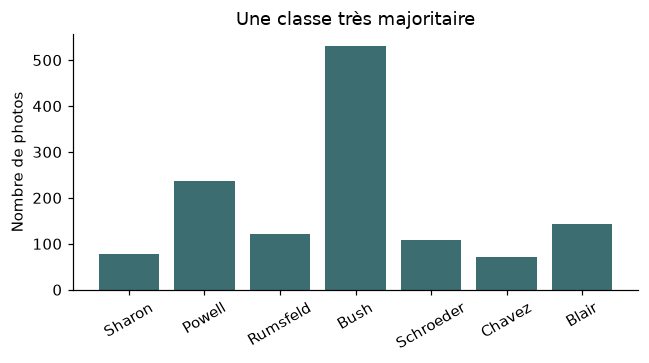

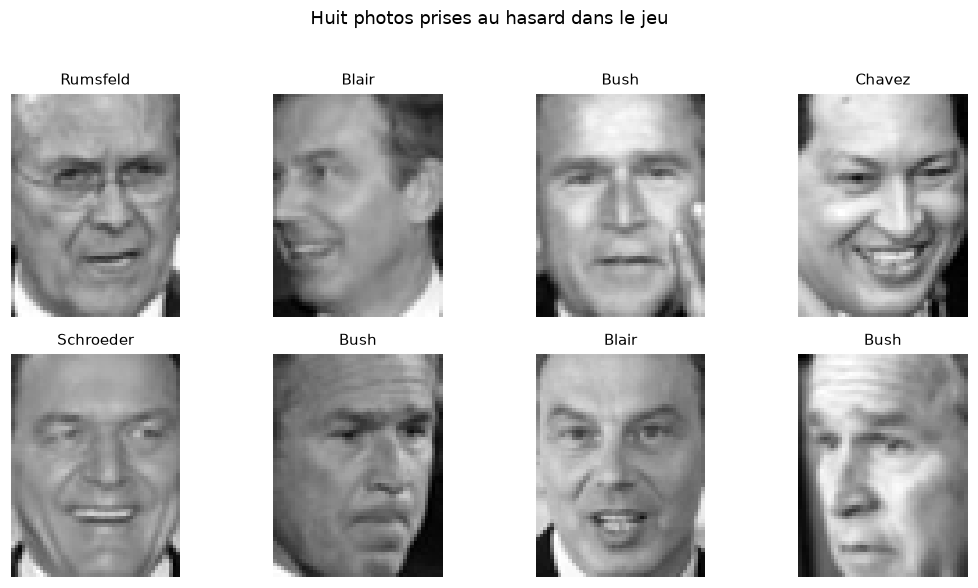

In [14]:
from sklearn.datasets import fetch_lfw_people

visages = fetch_lfw_people(min_faces_per_person=70, color=False, download_if_missing=True)
images = visages.images
X_visages = images.reshape(images.shape[0], -1)
y_visages = visages.target
noms = [nom.split()[-1] for nom in visages.target_names]

print(f"{images.shape[0]} photos, {images.shape[1]}×{images.shape[2]} pixels, {len(noms)} personnes.")
print(f"Chaque photo devient un vecteur de {X_visages.shape[1]} attributs.")

effectifs = np.bincount(y_visages)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(noms, effectifs, color="#3c6e71")
ax.set_ylabel("Nombre de photos")
ax.set_title("Une classe très majoritaire")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

indices_exemple = np.random.default_rng(0).choice(len(y_visages), size=8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(10, 5.2))
for ax, indice in zip(axes.ravel(), indices_exemple):
    ax.imshow(images[indice], cmap="gray")
    ax.set_title(noms[y_visages[indice]], fontsize=10)
    ax.axis("off")
fig.suptitle("Huit photos prises au hasard dans le jeu", y=1.02)
fig.tight_layout()
plt.show()


In [15]:
X_app_v, X_eval_v, y_app_v, y_eval_v, indices_app, indices_eval = train_test_split(
    X_visages,
    y_visages,
    np.arange(len(y_visages)),
    test_size=0.33,
    random_state=666,
    stratify=y_visages,
)

baseline_v = DummyClassifier(strategy="most_frequent").fit(X_app_v, y_app_v)
classes_v, centroides_v = entrainer_centroide(X_app_v, y_app_v)
knn_v = KNeighborsClassifier(n_neighbors=10).fit(X_app_v, y_app_v)
arbre_v = DecisionTreeClassifier(max_depth=6, random_state=0).fit(X_app_v, y_app_v)
foret_v = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_app_v, y_app_v)

predictions = {
    "Baseline": baseline_v.predict(X_eval_v),
    "Centroïde": predire_centroide(X_eval_v, classes_v, centroides_v),
    "KNN (k=10)": knn_v.predict(X_eval_v),
    "Arbre (profondeur=6)": arbre_v.predict(X_eval_v),
    "Forêt (200 arbres)": foret_v.predict(X_eval_v),
}

print(f"{'Classifieur':24}{'Exactitude':>12}{'F1 macro':>12}")
for nom_modele, y_pred in predictions.items():
    exactitude = accuracy_score(y_eval_v, y_pred)
    f1_macro = f1_score(y_eval_v, y_pred, average="macro")
    print(f"{nom_modele:24}{exactitude:12.3f}{f1_macro:12.3f}")


Classifieur               Exactitude    F1 macro
Baseline                       0.411       0.083
Centroïde                      0.373       0.362
KNN (k=10)                     0.554       0.325
Arbre (profondeur=6)           0.441       0.297
Forêt (200 arbres)             0.631       0.444


### Interpréter l'écart entre exactitude et F1 macro

| Classifieur | Exactitude | F1 macro |
|---|---:|---:|
| Baseline | 0,411 | 0,083 |
| Centroïde | 0,373 | 0,362 |
| KNN (k=10) | 0,554 | 0,325 |
| Arbre (profondeur=6) | 0,441 | 0,297 |
| Forêt (200 arbres) | 0,631 | 0,444 |

La personne la plus photographiée représente 41 % des photos. La baseline, qui prédit toujours cette personne, obtient donc une exactitude de 0,411 pour un F1 macro de seulement 0,083 : les six autres personnes n'ont jamais la bonne réponse.

La forêt arrive en tête des deux repères (exactitude 0,631, F1 macro 0,444). Mais le reste du classement change selon la colonne lue. En exactitude : forêt, puis KNN (0,554), puis arbre (0,441), puis centroïde (0,373) — moins bon que la baseline elle-même. En F1 macro : forêt, puis **centroïde** (0,362), puis KNN (0,325), puis arbre (0,297). Le centroïde, dernier en exactitude, devance le KNN et l'arbre en F1 macro : il se trompe plus souvent au total, mais ses erreurs se répartissent plus également entre les sept personnes, faute de pouvoir se spécialiser sur la plus fréquente. L'arbre, à l'inverse, est deuxième en exactitude et dernier en F1 macro parmi les quatre classifieurs : une partie de son score d'exactitude vient de prédictions concentrées sur la personne majoritaire.


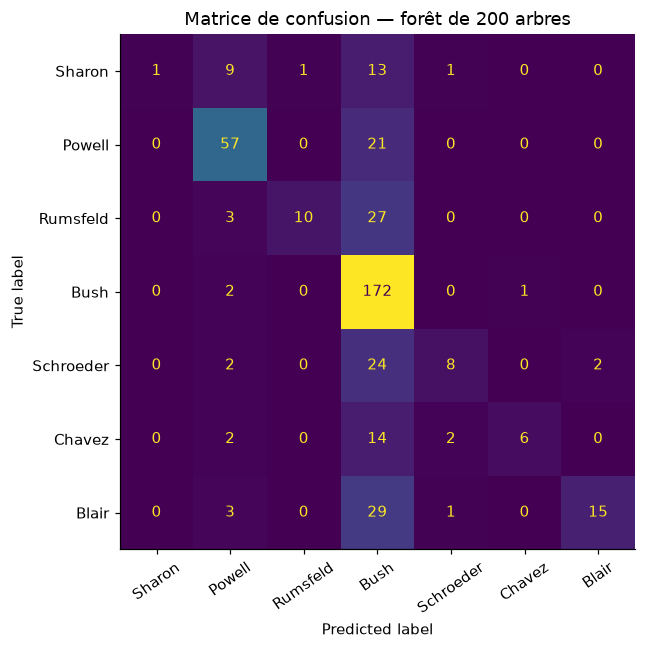

In [16]:
fig, ax = plt.subplots(figsize=(6.2, 6))
ConfusionMatrixDisplay.from_predictions(
    y_eval_v,
    predictions["Forêt (200 arbres)"],
    display_labels=noms,
    ax=ax,
    xticks_rotation=35,
    colorbar=False,
)
ax.set_title("Matrice de confusion — forêt de 200 arbres")
fig.tight_layout()
plt.show()


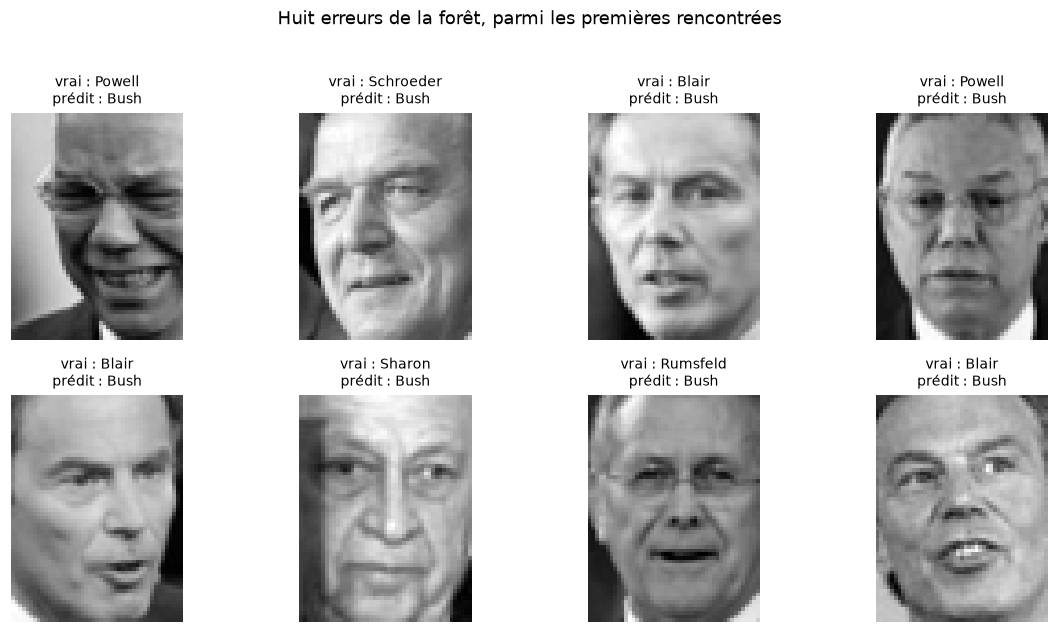

In [17]:
y_pred_foret = predictions["Forêt (200 arbres)"]
mal_classes = np.where(y_pred_foret != y_eval_v)[0][:8]

fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for ax, position in zip(axes.ravel(), mal_classes):
    indice_photo = indices_eval[position]
    ax.imshow(images[indice_photo], cmap="gray")
    vrai = noms[y_eval_v[position]]
    predit = noms[y_pred_foret[position]]
    ax.set_title(f"vrai : {vrai}\nprédit : {predit}", fontsize=9)
    ax.axis("off")
fig.suptitle("Huit erreurs de la forêt, parmi les premières rencontrées", y=1.02)
fig.tight_layout()
plt.show()


### Interpréter la matrice de confusion

La colonne de la personne majoritaire est la plus remplie de toute la matrice, y compris sur des lignes qui ne la concernent pas : une partie des photos des six autres personnes y est classée par erreur. Les huit erreurs affichées confirment ce biais : la quasi-totalité des prédictions fautives de la forêt tombent sur cette même personne, quelle que soit l'identité réelle sur la photo.

Ce biais n'est pas propre à la forêt : il vient du déséquilibre des classes, visible dès le graphique en barres du début de section. Un modèle entraîné sur des données où une classe domine apprend, au moins en partie, à la reconnaître plus facilement que les autres — exactement le mécanisme déjà rencontré au niveau 1 avec la souscription bancaire, ici démultiplié par le nombre de classes. Lire seulement l'exactitude aurait caché cette faiblesse.


## Bilan

Le classifieur du plus proche centroïde fixe un repère simple : il réussit quand les classes sont des boules de taille comparable, et échoue dès qu'elles sont étirées, courbes ou concentriques, comme la section 9 l'a montré à plusieurs reprises. Les k plus proches voisins, l'arbre de décision et la forêt aléatoire gardent chacun un réglage à choisir par validation croisée, sur l'entraînement seul : `k` pour le KNN, la profondeur pour l'arbre. La forêt, elle, s'améliore avec le nombre d'arbres sans faire réapparaître le surapprentissage observé sur l'arbre isolé.

Sur le jeu synthétique, la forêt l'emporte de peu. Sur les visages, à haute dimension et avec des classes très déséquilibrées, le même classement en exactitude cache des écarts de F1 macro plus parlants : un modèle peut gagner en exactitude en devenant meilleur sur la classe majoritaire, sans mieux reconnaître les autres personnes.

### À réutiliser

- Dessiner une frontière de décision pour comprendre un classifieur, pas seulement lire un score.
- Choisir un hyperparamètre (`k`, profondeur) par validation croisée sur l'entraînement, jamais sur le test.
- Ajouter des arbres à une forêt améliore ou stabilise le résultat ; augmenter la profondeur d'un arbre isolé finit par le dégrader.
- Lire l'exactitude et le F1 macro ensemble dès que les classes ne sont pas équilibrées. Un grand écart entre les deux signale un modèle qui privilégie la classe la plus fréquente.

### Sources

- Jeu de visages : [LFW, Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/) et [`sklearn.datasets.fetch_lfw_people`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_lfw_people.html).
- Jeu de chiffres manuscrits : [`sklearn.datasets.load_digits`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
- Classifieurs : [plus proche centroïde](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestCentroid.html), [KNN](https://scikit-learn.org/stable/modules/neighbors.html), [arbres de décision](https://scikit-learn.org/stable/modules/tree.html), [forêts aléatoires](https://scikit-learn.org/stable/modules/ensemble.html#random-forests).

### Limites

Les jeux synthétiques de ce notebook sont volontairement simples et reproductibles grâce aux graines fixées. Les hyperparamètres choisis (`k=10`, profondeur 6, 200 arbres) sont adaptés au jeu de la section 2 ; les reprendre tels quels sur un autre jeu, comme la galerie de la section 9 le montre, donne des résultats différents selon la forme des classes. Sur les visages, le partage aléatoire entraînement/test peut placer dans le test des photos très proches de photos vues à l'entraînement, ce qui tend à optimiser les scores. Une évaluation plus rigoureuse séparerait les photos par séance ou par date de prise de vue, pour vérifier que le modèle reconnaît la personne plutôt que les conditions d'une photo précise.
